<a href="https://colab.research.google.com/github/scrayzk/solar-energy-prediction/blob/main/solar_energy_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Solar Energy Production Prediction (CS 316 – Phase 1)
Predicts solar power output from weather measurements using **pandas, numpy, seaborn and scikit-learn**.

**Before running:** download the dataset from Kaggle (https://www.kaggle.com/datasets/anikannal/solar-power-generation-data), unzip it, and keep the 4 CSV files:
`Plant_1_Generation_Data.csv`, `Plant_1_Weather_Sensor_Data.csv`, `Plant_2_Generation_Data.csv`, `Plant_2_Weather_Sensor_Data.csv`.
Then run the cells from top to bottom.

## 1. Imports
seaborn draws the charts (matplotlib is installed with it and only used to show them). scikit-learn provides the models and metrics.

In [71]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_style(style="whitegrid")

## 2. Get the data from GitHub
This downloads the repo, including the data/ folder, into Colab.

In [87]:
!git clone https://github.com/scrayzk/solar-energy-prediction.git
%cd solar-energy-prediction

Cloning into 'solar-energy-prediction'...
remote: Enumerating objects: 28, done.
remote: Counting objects: 100% (28/28), done.
remote: Compressing objects: 100% (22/22), done.
remote: Total 28 (delta 4), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (28/28), 2.33 MiB | 5.93 MiB/s, done.
Resolving deltas: 100% (4/4), done.
/content/solar-energy-prediction


## 3. Load the data
Each plant has a **generation** file (power from 22 inverters every 15 min) and a **weather** file (one sensor per plant).
Plant 1's generation file writes dates as day-month-year, so we tell pandas the format. The other files use the standard format.

In [72]:
gen1 = pd.read_csv("Plant_1_Generation_Data.csv")
gen2 = pd.read_csv("Plant_2_Generation_Data.csv")
w1 = pd.read_csv("Plant_1_Weather_Sensor_Data.csv")
w2 = pd.read_csv("Plant_2_Weather_Sensor_Data.csv")

gen1["DATE_TIME"] = pd.to_datetime(gen1["DATE_TIME"], format="%d-%m-%Y %H:%M")
for df in (gen2, w1, w2):
    df["DATE_TIME"] = pd.to_datetime(df["DATE_TIME"])

gen1.head()
#w1.head()

,DATE_TIME,PLANT_ID,SOURCE_KEY,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD
0,2020-05-15,4135001,1BY6WEcLGh8j5v7,0.0,0.0,0.0,6259559.0
1,2020-05-15,4135001,1IF53ai7Xc0U56Y,0.0,0.0,0.0,6183645.0
2,2020-05-15,4135001,3PZuoBAID5Wc2HD,0.0,0.0,0.0,6987759.0
3,2020-05-15,4135001,7JYdWkrLSPkdwr4,0.0,0.0,0.0,7602960.0
4,2020-05-15,4135001,McdE0feGgRqW7Ca,0.0,0.0,0.0,7158964.0


<Axes: xlabel='AC_POWER', ylabel='Count'>

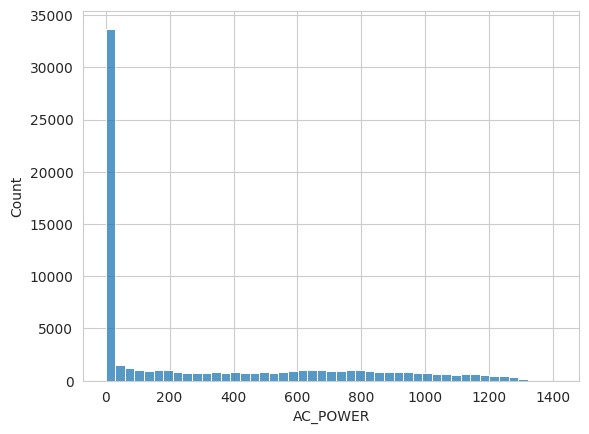

In [73]:
sns.histplot(gen1["AC_POWER"])

## 4. Clean and merge (Task: data collection and cleaning)
1. Stack the two plants together.
2. Check for missing values and duplicates, and remove them.
3. The generation file has many inverters per timestamp, so we take the **average AC power per inverter** for each plant and timestamp. This matches the plant-level weather readings (one row per timestamp).
4. Merge generation and weather on `DATE_TIME` + `PLANT_ID`.

In [85]:
gen = pd.concat([gen1, gen2], ignore_index=True)
weather = pd.concat([w1, w2], ignore_index=True)

print("Missing values in generation data:\n", gen.isna().sum(), "\n")
print("Missing values in weather data:\n", weather.isna().sum(), "\n")

# One row per plant per timestamp: average AC power across inverters
power = gen.groupby(["DATE_TIME", "PLANT_ID"], as_index=False)["AC_POWER"].mean()

# Merge with weather (inner join keeps only timestamps that exist in both)
weather = weather[["DATE_TIME", "PLANT_ID", "AMBIENT_TEMPERATURE", "MODULE_TEMPERATURE", "IRRADIATION"]]
data = power.merge(weather, on=["DATE_TIME", "PLANT_ID"], how="inner")

print("Merged dataset shape:", data.shape)
data.head()

Missing values in generation data:
 DATE_TIME      0
PLANT_ID       0
SOURCE_KEY     0
DC_POWER       0
AC_POWER       0
DAILY_YIELD    0
TOTAL_YIELD    0
dtype: int64 

Missing values in weather data:
 DATE_TIME              0
PLANT_ID               0
SOURCE_KEY             0
AMBIENT_TEMPERATURE    0
MODULE_TEMPERATURE     0
IRRADIATION            0
dtype: int64 

Merged dataset shape: (6416, 6)


,DATE_TIME,PLANT_ID,AC_POWER,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
0,2020-05-15 00:00:00,4135001,0.0,25.184316,22.857507,0.0
1,2020-05-15 00:00:00,4136001,0.0,27.004764,25.060789,0.0
2,2020-05-15 00:15:00,4135001,0.0,25.084589,22.761668,0.0
3,2020-05-15 00:15:00,4136001,0.0,26.880811,24.421869,0.0
4,2020-05-15 00:30:00,4135001,0.0,24.935753,22.592306,0.0


In [75]:
print("Plant-timestamps in generation data:", len(power))
print("Weather rows:", len(weather))
print("After merge: ", len(data))

Plant-timestamps in generation data: 6417
Weather rows: 6441
After merge:  6416


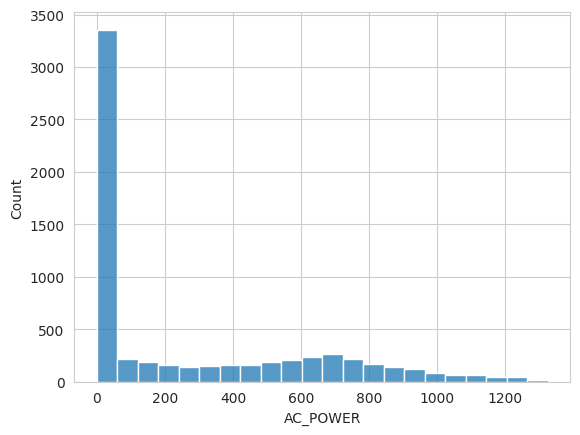

In [86]:
sns.histplot(data["AC_POWER"])
plt.show()

## 5. Feature engineering
New columns that help the models:
- `PLANT`: 1 or 2 (plants behave a little differently).
- `HOUR`: time of day as a number (e.g. 13.5 = 1:30 pm). Solar output follows the sun.
- `TEMP_DIFF`: module temperature minus ambient temperature.

At night the panels produce nothing and irradiation is 0, which is trivially easy to predict and would inflate our scores.
So we keep **daytime rows only** (`IRRADIATION > 0`).

In [77]:
data["PLANT"] = data["PLANT_ID"].map({4135001: 1, 4136001: 2})
data["HOUR"] = data["DATE_TIME"].dt.hour + data["DATE_TIME"].dt.minute / 60
data["TEMP_DIFF"] = data["MODULE_TEMPERATURE"] - data["AMBIENT_TEMPERATURE"]

data = data[data["IRRADIATION"] > 0].reset_index(drop=True)

features = ["IRRADIATION", "AMBIENT_TEMPERATURE", "MODULE_TEMPERATURE", "TEMP_DIFF", "HOUR", "PLANT"]
target = "AC_POWER"

data[features + [target]].describe().round(2)

,IRRADIATION,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,TEMP_DIFF,HOUR,PLANT,AC_POWER
count,3616.00,3616.00,3616.00,3616.00,3616.00,3616.00,3616.00
mean,0.41,28.71,39.05,10.35,12.28,1.51,485.47
std,0.31,3.90,11.38,8.87,3.95,0.50,342.03
min,0.00,20.40,18.24,-3.76,0.00,1.00,0.00
25%,0.12,25.74,29.09,2.02,9.00,1.00,162.84
50%,0.39,28.36,38.70,9.57,12.25,2.00,498.88
75%,0.67,31.55,48.55,17.68,15.56,2.00,740.12
max,1.22,39.18,66.64,35.24,23.75,2.00,1325.01


In [78]:
data.shape

(3616, 9)

## 6. Exploratory data analysis
Three charts: how strongly each variable relates to power (heatmap), power vs. irradiation, and the daily power curve.

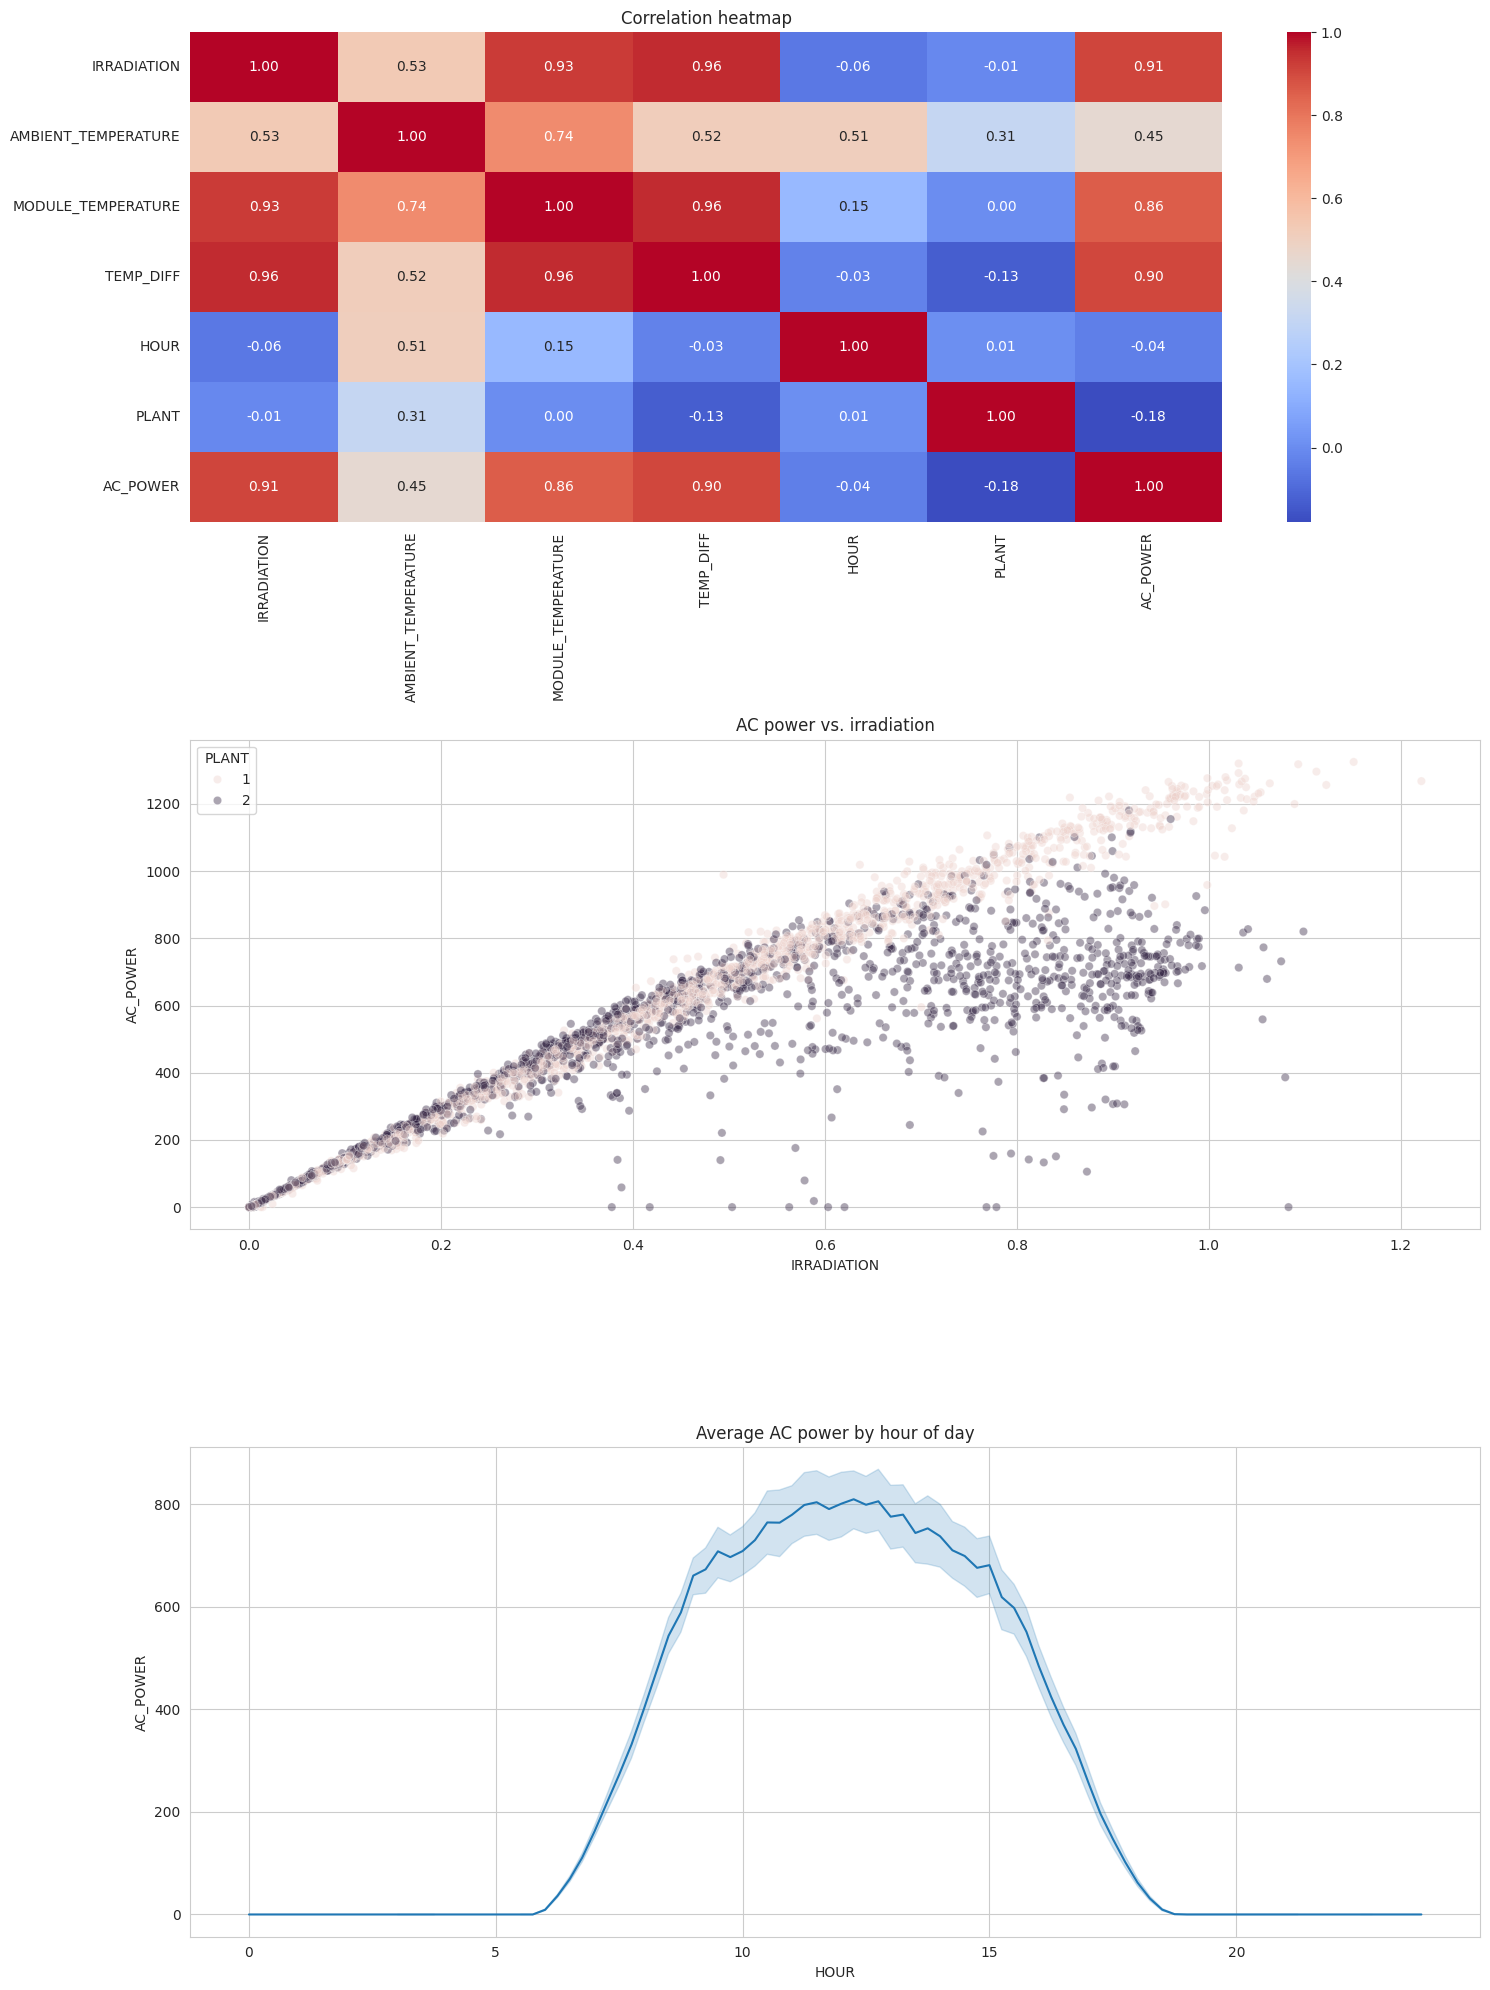

In [79]:
fig, axes = plt.subplots(3, 1, figsize=(15, 20))

sns.heatmap(data[features + [target]].corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=axes[0])
axes[0].set_title("Correlation heatmap")

sns.scatterplot(data=data, x="IRRADIATION", y="AC_POWER", hue="PLANT", alpha=0.4, ax=axes[1])
axes[1].set_title("AC power vs. irradiation")

sns.lineplot(data=data, x="HOUR", y="AC_POWER", ax=axes[2])
axes[2].set_title("Average AC power by hour of day")

plt.tight_layout()
plt.show()

## 7. Train / test split
Weather data is a time series, so a random split would "leak" neighbouring 15-minute rows into both sets.
Instead we train on the **first 80% of days** and test on the **last 20%**. This tests how well the model predicts days it has never seen.

In [80]:
days = np.sort(data["DATE_TIME"].dt.normalize().unique())
cutoff = days[int(len(days) * 0.8)]

train = data[data["DATE_TIME"] < cutoff]
test = data[data["DATE_TIME"] >= cutoff]

X_train, y_train = train[features], train[target]
X_test, y_test = test[features], test[target]

print(f"Train: {len(train)} rows | Test: {len(test)} rows | Test starts on {str(cutoff)[:10]}")

Train: 2862 rows | Test: 754 rows | Test starts on 2020-06-11


## 8. Train and compare the models (Task: model development + evaluation)
We train 3 regression models and score each on the unseen test days with:
- **MAE**: average error in kW (easy to read).
- **RMSE**: like MAE but punishes big misses more.
- **R²**: share of the variation in power the model explains (1.0 is perfect).

In [81]:
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=8, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
}

rows, predictions = [], {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    predictions[name] = pred
    rows.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred),
    })

results = pd.DataFrame(rows).set_index("Model").sort_values("RMSE").round(3)
results

,MAE,RMSE,R2
Model,,,
Random Forest,35.135,77.949,0.935
Decision Tree,37.530,85.441,0.922
Linear Regression,97.960,125.807,0.831


## 9. Visualise the results
Left: RMSE per model (lower is better). Middle: predicted vs. actual power for the best model (points on the red line are perfect predictions). Right: correlation of each feature with AC power. The further a bar is from zero, the stronger the relationship. A positive bar means power rises as the feature rises, and a negative bar means it falls.

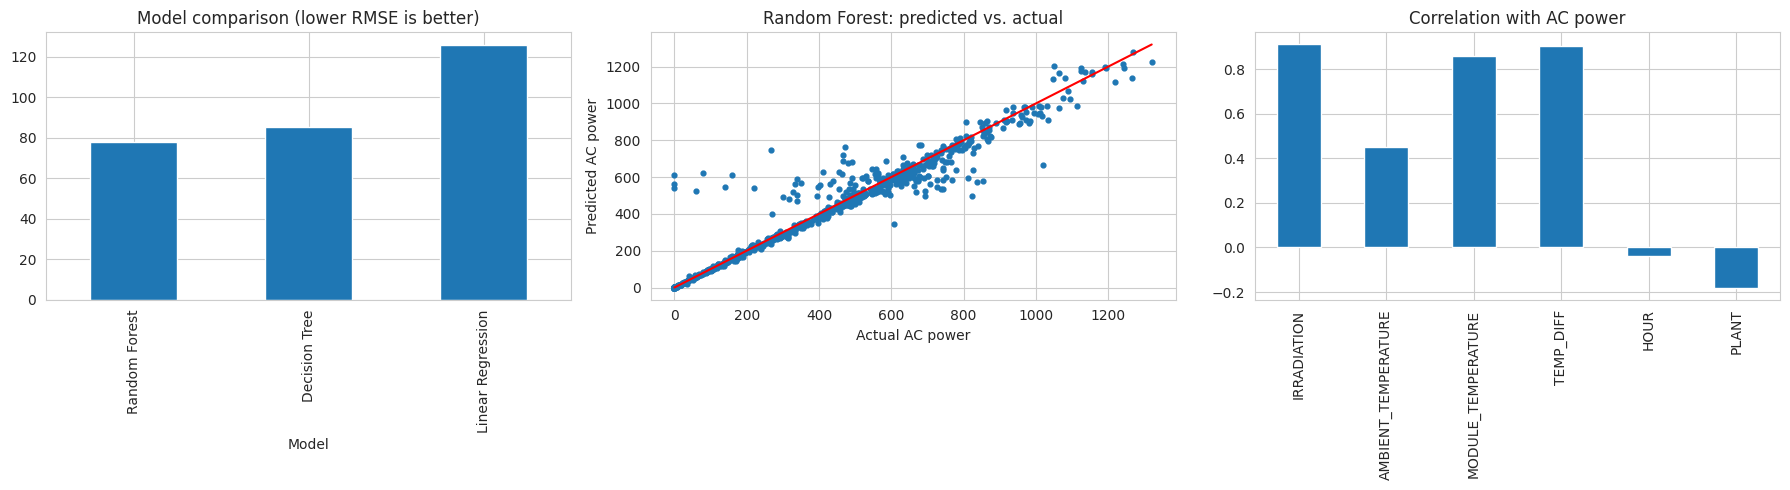

In [82]:
best_name = results.index[0]
best_model = models[best_name]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

results["RMSE"].plot(kind="bar", ax=axes[0])
axes[0].set_title("Model comparison (lower RMSE is better)")

axes[1].scatter(y_test, predictions[best_name],s=12)
axes[1].plot([0, y_test.max()], [0, y_test.max()], color="red")
axes[1].set_xlabel("Actual AC power")
axes[1].set_ylabel("Predicted AC power")
axes[1].set_title(f"{best_name}: predicted vs. actual")

corrs= data[features + [target]].corr()[target].drop(target)
corrs.plot(kind="bar", ax=axes[2])
axes[2].set_title("Correlation with AC power")

plt.tight_layout()
plt.show()

## 10. Fill in the summary
This prints the project summary with the blanks from your abstract filled in automatically.

In [83]:
best = results.loc[best_name]
top_feature = corrs.abs().idxmax()

print(
    "Solar power output fluctuates with weather conditions, complicating grid planning and increasing "+"\n"+
    "reliance on fossil-fuel backup generation. This project builds a supervised regression pipeline that "+"\n"+
    "predicts solar power generation from weather measurements, using 34 days of 15-minute interval data "+"\n"+
    "from two grid-connected solar plants in India. Generation and weather records were merged, cleaned, "+"\n"+
    f"and enriched with engineered features, then used to train and compare {len(models)} regression models "+"\n"+
    f"evaluated with MAE, RMSE, and R². The best-performing model was {best_name} "+"\n"+
    f"(MAE = {best['MAE']:.2f} kW, RMSE = {best['RMSE']:.2f} kW, R² = {best['R2']:.3f}), "+"\n"+
    f"and the main driver of solar output was {top_feature}. The results illustrate how better forecasting "+"\n"+
    "can support renewable-energy integration and reduce dependence on backup fossil-fuel generation."+"\n"
)

Solar power output fluctuates with weather conditions, complicating grid planning and increasing 
reliance on fossil-fuel backup generation. This project builds a supervised regression pipeline that 
predicts solar power generation from weather measurements, using 34 days of 15-minute interval data 
from two grid-connected solar plants in India. Generation and weather records were merged, cleaned, 
and enriched with engineered features, then used to train and compare 3 regression models 
evaluated with MAE, RMSE, and R². The best-performing model was Random Forest 
(MAE = 35.13 kW, RMSE = 77.95 kW, R² = 0.935), 
and the main driver of solar output was IRRADIATION. The results illustrate how better forecasting 
can support renewable-energy integration and reduce dependence on backup fossil-fuel generation.

